# Experiment 6: Naive Bayes - Confusion Matrix and Accuracy
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program to implement the **Naive Bayes** algorithm in Python and display the results using a **confusion matrix** and **accuracy**.

## Theory
Bayes theorem with the "naive" assumption that features are conditionally independent given the class:

`P(C | x1..xn)  is proportional to  P(C) * prod_i P(x_i | C)`

For continuous features, `P(x_i | C)` is modelled with a Gaussian (Gaussian Naive Bayes). The data set used is the *Wine* data set (3 classes, 13 features).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

wine = load_wine()
X, y = wine.data, wine.target
print('Samples:', X.shape[0], '| Features:', X.shape[1], '| Classes:', wine.target_names.tolist())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

Samples: 178 | Features: 13 | Classes: ['class_0', 'class_1', 'class_2']


In [2]:
# --- From-scratch Gaussian Naive Bayes ---
class MyGaussianNB:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.prior = np.array([np.mean(y == c) for c in self.classes])
        self.mean = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.var = np.array([X[y == c].var(axis=0) + 1e-9 for c in self.classes])
        return self

    def predict(self, X):
        log_post = []
        for i, c in enumerate(self.classes):
            log_lik = -0.5 * np.sum(np.log(2 * np.pi * self.var[i]) + (X - self.mean[i]) ** 2 / self.var[i], axis=1)
            log_post.append(np.log(self.prior[i]) + log_lik)
        return self.classes[np.argmax(np.array(log_post), axis=0)]

mine = MyGaussianNB().fit(X_train, y_train)
print('From-scratch accuracy:', round(accuracy_score(y_test, mine.predict(X_test)), 4))

# --- scikit-learn ---
gnb = GaussianNB().fit(X_train, y_train)
y_pred = gnb.predict(X_test)
print('scikit-learn accuracy:', round(accuracy_score(y_test, y_pred), 4))

From-scratch accuracy: 1.0
scikit-learn accuracy: 1.0


Confusion matrix:
 [[18  0  0]
 [ 0 21  0]
 [ 0  0 15]]

Accuracy: 100.0 %

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



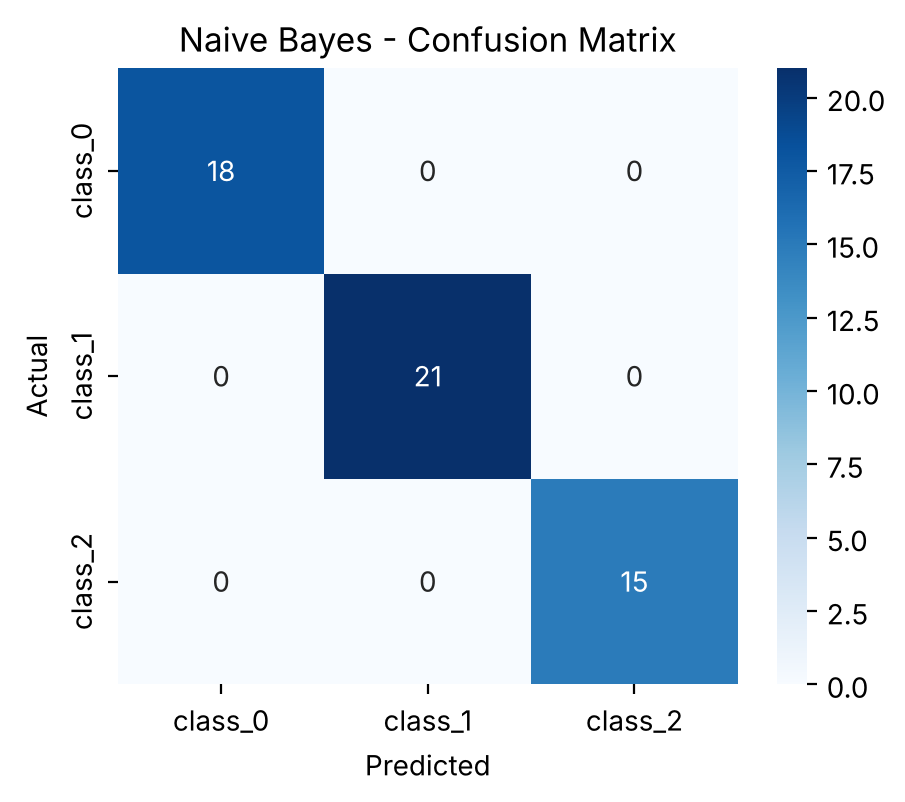

In [3]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix:\n', cm)
print('\nAccuracy:', round(accuracy_score(y_test, y_pred) * 100, 2), '%\n')
print(classification_report(y_test, y_pred, target_names=wine.target_names))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Naive Bayes - Confusion Matrix')
plt.show()

## Result
Gaussian Naive Bayes classifies the three wine cultivars with very high accuracy (every test sample is classified correctly on this split, so the confusion matrix is purely diagonal). The from-scratch implementation gives the same accuracy as scikit-learn.